# Task: Multiclass malware-family classification


Track: Track 3 — CNN + Attention


Proposed model: CNN with a channel or spatial attention module

Upload Dataset


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/malimg_paper_dataset_imgs.zip'
extract_path = '/content/malimg'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

print(os.listdir('/content/malimg'))

['Lolyda.AA1', 'Wintrim.BX', 'Instantaccess', 'Autorun.K', 'Rbot!gen', 'Lolyda.AT', 'C2LOP.gen!g', 'Swizzor.gen!E', 'Malex.gen!J', 'Adialer.C', 'Yuner.A', 'C2LOP.P', 'Obfuscator.AD', 'Lolyda.AA3', 'Agent.FYI', 'Skintrim.N', 'Allaple.A', 'Allaple.L', 'Dialplatform.B', 'VB.AT', 'Dontovo.A', 'Swizzor.gen!I', 'Lolyda.AA2', 'Fakerean', 'Alueron.gen!J']


Import Libraries


In [ ]:
from pathlib import Path
from collections import Counter

from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from pathlib import Path

# Change this path to your actual dataset folder
DATA_DIR = Path("/content/malimg")

print("Folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for item in list(DATA_DIR.iterdir())[:20]:
        print(item.name, "—", "folder" if item.is_dir() else "file")

Folder exists: True
Lolyda.AA1 — folder
Wintrim.BX — folder
Instantaccess — folder
Autorun.K — folder
Rbot!gen — folder
Lolyda.AT — folder
C2LOP.gen!g — folder
Swizzor.gen!E — folder
Malex.gen!J — folder
Adialer.C — folder
Yuner.A — folder
C2LOP.P — folder
Obfuscator.AD — folder
Lolyda.AA3 — folder
Agent.FYI — folder
Skintrim.N — folder
Allaple.A — folder
Allaple.L — folder
Dialplatform.B — folder
VB.AT — folder


count every image

In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/malimg")

data = []

for class_dir in DATA_DIR.iterdir():
    if class_dir.is_dir():
        for image_file in class_dir.iterdir():
            if image_file.is_file():
                data.append({
                    "class": class_dir.name,
                    "image_path": str(image_file)
                })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("Total classes:", df["class"].nunique())

print("\nImages per class:")
print(df["class"].value_counts())

Total images: 9339
Total classes: 25

Images per class:
class
Allaple.A         2949
Allaple.L         1591
Yuner.A            800
Instantaccess      431
VB.AT              408
Fakerean           381
Lolyda.AA1         213
C2LOP.gen!g        200
Alueron.gen!J      198
Lolyda.AA2         184
Dialplatform.B     177
Dontovo.A          162
Lolyda.AT          159
Rbot!gen           158
C2LOP.P            146
Obfuscator.AD      142
Malex.gen!J        136
Swizzor.gen!I      132
Swizzor.gen!E      128
Lolyda.AA3         123
Adialer.C          122
Agent.FYI          116
Autorun.K          106
Wintrim.BX          97
Skintrim.N          80
Name: count, dtype: int64


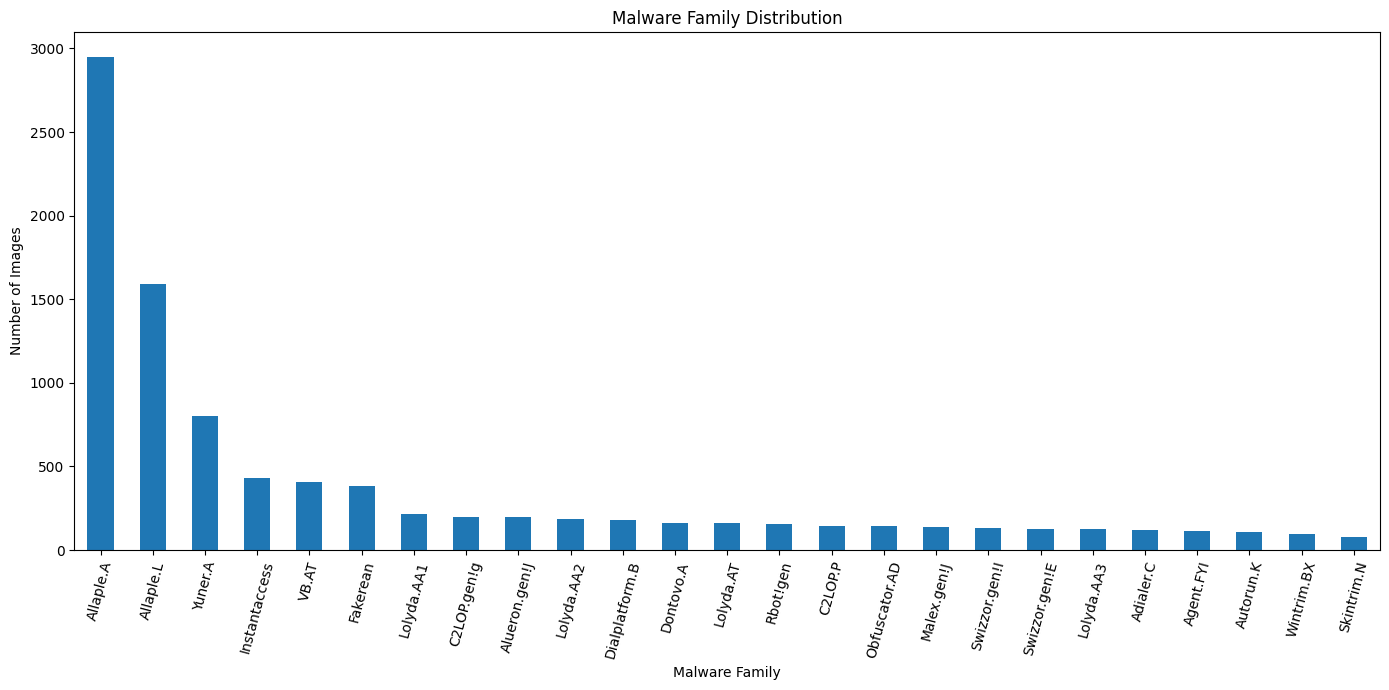

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["class"].value_counts()

plt.figure(figsize=(14, 7))

class_counts.plot(kind="bar")

plt.title("Malware Family Distribution")
plt.xlabel("Malware Family")
plt.ylabel("Number of Images")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

# EDA


Sample image grid


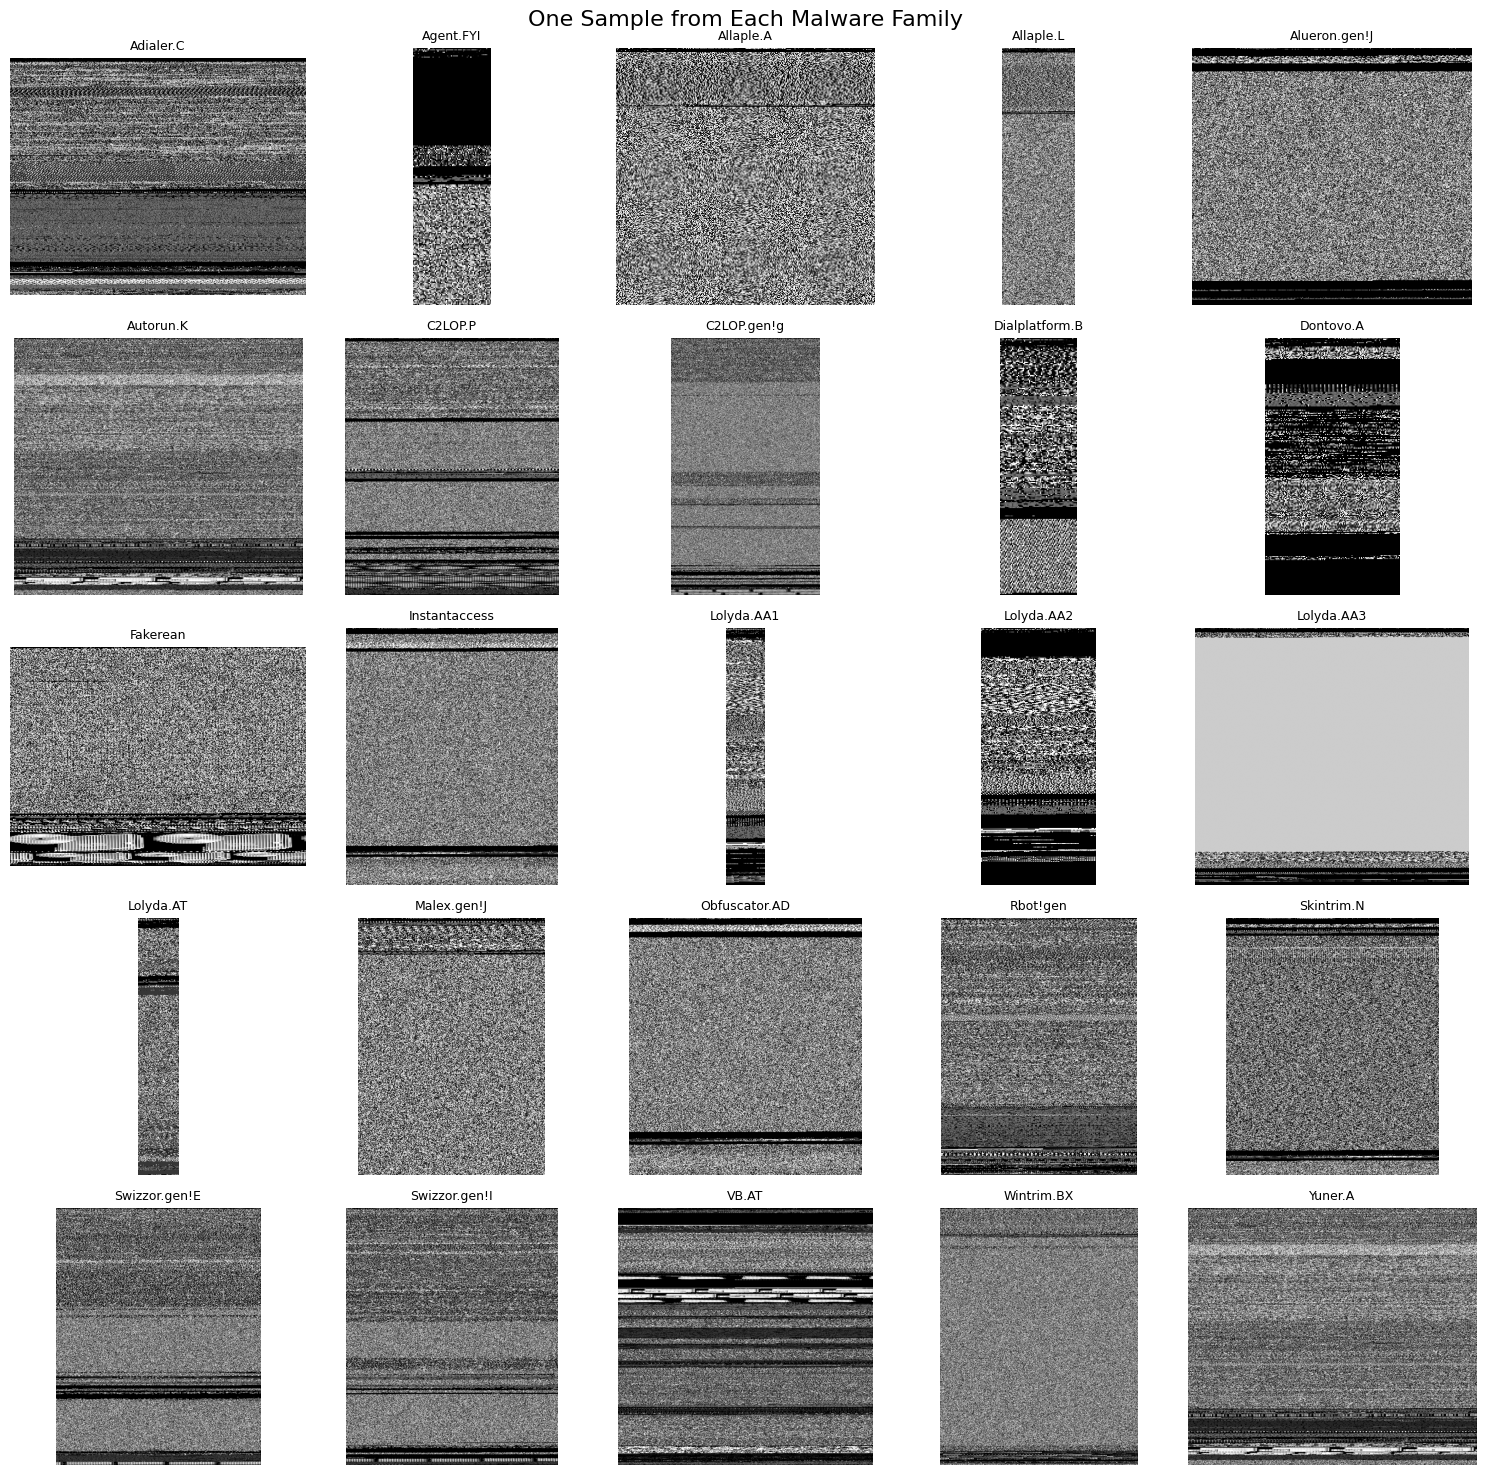

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = sorted(df["class"].unique())

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for ax, class_name in zip(axes.ravel(), classes):
    class_images = df[df["class"] == class_name]["image_path"].tolist()
    image_path = random.choice(class_images)

    img = Image.open(image_path)

    ax.imshow(img, cmap="gray")
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.suptitle("One Sample from Each Malware Family", fontsize=16)
plt.tight_layout()
plt.show()

Image dimensions / resolution

In [ ]:
from PIL import Image
from collections import Counter

widths = []
heights = []
modes = []
bad_images = []

for path in df["image_path"]:
    try:
        img = Image.open(path)
        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)
    except Exception:
        bad_images.append(path)

print("Unreadable images:", len(bad_images))

print("\nImage modes:")
print(Counter(modes))

print("\nWidth statistics:")
print(pd.Series(widths).describe())

print("\nHeight statistics:")
print(pd.Series(heights).describe())

Unreadable images: 0

Image modes:
Counter({'L': 9339})

Width statistics:
count    9339.000000
mean      334.171967
std       218.421689
min        64.000000
25%       128.000000
50%       256.000000
75%       512.000000
max      1024.000000
dtype: float64

Height statistics:
count    9339.000000
mean      436.814541
std       203.640501
min       208.000000
25%       281.000000
50%       424.000000
75%       467.000000
max      5334.000000
dtype: float64


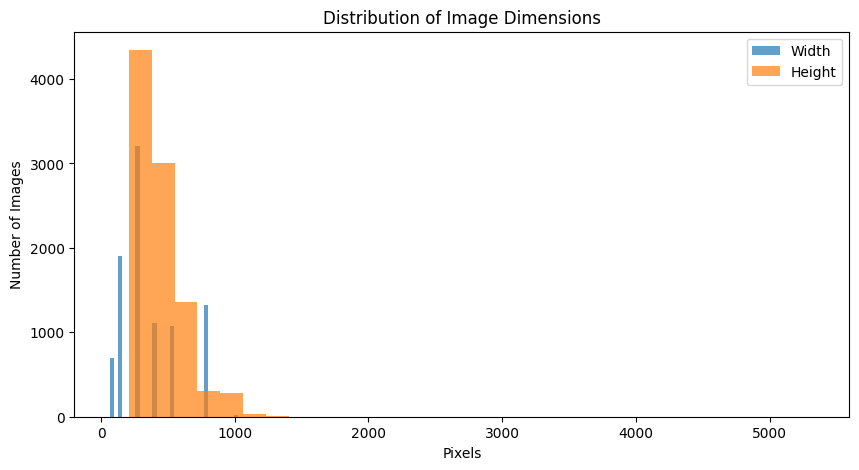

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(widths, bins=30, alpha=0.7, label="Width")
plt.hist(heights, bins=30, alpha=0.7, label="Height")

plt.xlabel("Pixels")
plt.ylabel("Number of Images")
plt.title("Distribution of Image Dimensions")
plt.legend()
plt.show()

Pixel / grayscale analysis

In [ ]:
import numpy as np

pixel_means = []
pixel_stds = []
pixel_mins = []
pixel_maxs = []

# Analyze a sample of images to keep EDA fast
sample_df = df.sample(min(1000, len(df)), random_state=42)

for path in sample_df["image_path"]:
    try:
        img = Image.open(path).convert("L")
        arr = np.array(img)

        pixel_means.append(arr.mean())
        pixel_stds.append(arr.std())
        pixel_mins.append(arr.min())
        pixel_maxs.append(arr.max())
    except:
        pass

print("Mean pixel value:", np.mean(pixel_means))
print("Mean pixel std:", np.mean(pixel_stds))
print("Minimum pixel value:", np.min(pixel_mins))
print("Maximum pixel value:", np.max(pixel_maxs))

Mean pixel value: 112.90452064957893
Mean pixel std: 79.40088074326101
Minimum pixel value: 0
Maximum pixel value: 255


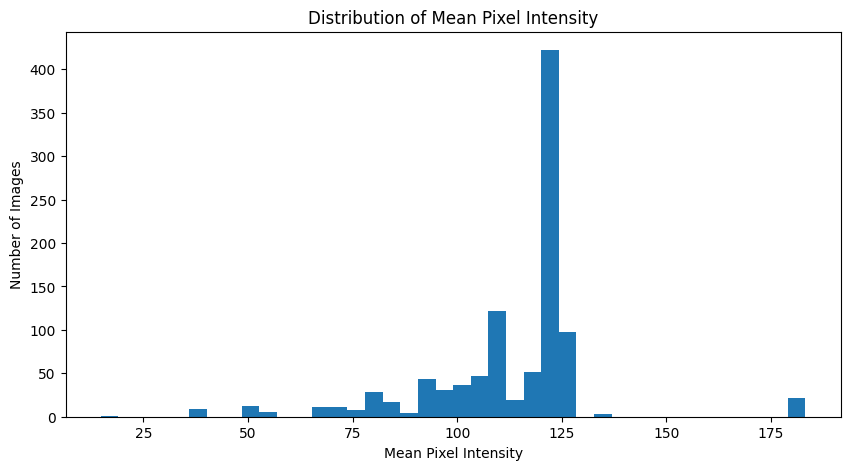

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(pixel_means, bins=40)

plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.title("Distribution of Mean Pixel Intensity")

plt.show()

Image quality

In [ ]:
quality_results = []

for path in df["image_path"]:
    try:
        img = Image.open(path)
        img.verify()

        img = Image.open(path)

        quality_results.append({
            "path": path,
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "valid": True
        })

    except Exception:
        quality_results.append({
            "path": path,
            "width": None,
            "height": None,
            "mode": None,
            "valid": False
        })

quality_df = pd.DataFrame(quality_results)

print("Total files:", len(quality_df))
print("Valid images:", quality_df["valid"].sum())
print("Invalid images:", (~quality_df["valid"]).sum())

Total files: 9339
Valid images: 9339
Invalid images: 0


In [ ]:
quality_df["area"] = quality_df["width"] * quality_df["height"]

print(
    quality_df[
        quality_df["area"] < quality_df["area"].quantile(0.01)
    ][["width", "height", "path"]].head(10)
)

      width  height                                               path
2965     64     209  /content/malimg/Agent.FYI/07310a8e5541a217284d...
2971     64     210  /content/malimg/Agent.FYI/05136f2bbee69dc20948...
2977     64     210  /content/malimg/Agent.FYI/07e549eae0812fc67eac...
2980     64     211  /content/malimg/Agent.FYI/002bb62e80912094ff98...
2984     64     211  /content/malimg/Agent.FYI/0838c0449c2974662e35...
2995     64     212  /content/malimg/Agent.FYI/047115e9fafecf8786d7...
2998     64     210  /content/malimg/Agent.FYI/07e7a5ae8d2f90be315f...
3000     64     209  /content/malimg/Agent.FYI/04814e5b6598cd203076...
3003     64     209  /content/malimg/Agent.FYI/006f68174627fbd86f42...
3010     64     210  /content/malimg/Agent.FYI/0827f456b46c9d99a218...


Interactive Plot

In [ ]:
!pip install -q plotly

In [ ]:
import plotly.express as px

interactive_counts = (
    df["class"]
    .value_counts()
    .reset_index()
)

interactive_counts.columns = ["class", "count"]

fig = px.bar(
    interactive_counts,
    x="class",
    y="count",
    title="Interactive Malware Family Distribution",
    labels={
        "class": "Malware Family",
        "count": "Number of Images"
    }
)

fig.update_layout(
    xaxis_tickangle=-60
)

fig.show()

Dataset summary table

In [ ]:
summary = {
    "Dataset": "Malimg Original",
    "Total Images": len(df),
    "Number of Classes": df["class"].nunique(),
    "Largest Class": class_counts.idxmax(),
    "Largest Class Count": class_counts.max(),
    "Smallest Class": class_counts.idxmin(),
    "Smallest Class Count": class_counts.min(),
    "Majority/Minority Ratio": round(
        class_counts.max() / class_counts.min(), 2
    ),
    "Unreadable Images": len(bad_images)
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Property", "Value"]
)

summary_df

,Property,Value
0,Dataset,Malimg Original
1,Total Images,9339
2,Number of Classes,25
3,Largest Class,Allaple.A
4,Largest Class Count,2949
5,Smallest Class,Skintrim.N
6,Smallest Class Count,80
7,Majority/Minority Ratio,36.86
8,Unreadable Images,0


Main EDA finding
The Malimg dataset contains 9,339 grayscale malware byte-images distributed across 25 malware families. The class distribution is highly imbalanced: Allaple.A contains 2,949 samples whereas Skintrim.N contains only 80, resulting in a majority-to-minority ratio of approximately 36.86:1. Therefore, overall accuracy alone may hide poor performance on minority malware families. Macro-F1 and per-class recall should be emphasized during model evaluation.

9,339 malware images

25 malware families

Grayscale byte-image representation

Multiclass malware-family classification

Strong class imbalance

Largest class: Allaple.A — 2,949

Smallest class: Skintrim.N — 80

Majority/minority ratio: 36.86:1